# Imports

In [310]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import base64
import seaborn as sns

In [311]:
import pickle

In [312]:
import ast

In [313]:
import ratinabox
from ratinabox.Environment import Environment
from ratinabox.Agent import Agent
from ratinabox.Neurons import FieldOfViewOVCs
# from ratinabox.Neurons import PlaceCells, GridCells #...

## aux funcs

In [314]:
import random
import string

def generate_random_string(n):
    """
    Generate a random string of length n.

    Parameters:
    n (int): The desired length of the string.

    Returns:
    str: A random string of length n.
    """
    if n <= 0:
        raise ValueError("Length 'n' must be a positive integer.")

    # Combine letters, digits, and punctuation
    characters = string.ascii_uppercase
    
    # Generate a random string of length n
    random_string = ''.join(random.choices(characters, k=n))

    return random_string


In [315]:
generate_random_string(8)

'CAORZALF'

In [316]:
def generate_all_positions_on_env(hole=None):

        # Define the range and step size
    step = 0.001  # Adjust the step size for granularity
    x_range = np.arange(0, 1 + step, step)
    y_range = np.arange(0, 1 + step, step)

    # Create a grid of (x, y) positions
    x, y = np.meshgrid(x_range, y_range)
    positions = np.column_stack([x.ravel(), y.ravel()])

    # Convert to a pandas DataFrame
    df_positions = pd.DataFrame(positions, columns=["X", "Y"])
    # df_positions['is_valid'] = [int(is_point_valid(pos, hole)) for pos in positions]
    df_positions['pos'] = [val for val in positions]

    return df_positions

In [317]:
def get_euclidean_distance(pos1, pos2):
    return np.sqrt((pos1[0] - pos2[0])**2 + ((pos1[1] - pos2[1])**2))
def apply_eucd_dist(x, obj=9):
    return get_euclidean_distance(x['pos'], x[f'obj_{obj}_pos'])

In [318]:
def gerar_grade_quadrada(n):
    """
    Gera uma lista de pontos (x, y) uniformemente distribuídos
    em uma grade quadrada dentro do domínio [0, 1] x [0, 1].

    Parâmetros:
        n (int): número de divisões por eixo (resultando em n x n pontos)

    Retorna:
        lista de tuplas (x, y)
    """
    pontos = []
    passo = 1.0 / (n - 1)  # para incluir o ponto 1.0 no final

    for i in range(n):
        x = i * passo
        for j in range(n):
            y = j * passo
            pontos.append((x, y))
    
    return pontos

In [319]:
def gerar_grade_com_ruido(n, sigma=0.02):
    """
    Gera uma grade com n x n pontos (x, y) dentro do domínio [0, 1] x [0, 1],
    adicionando ruído gaussiano positivo ou negativo aos pontos,
    mas mantendo-os dentro dos limites do domínio.

    Parâmetros:
        n (int): número de divisões por eixo
        sigma (float): desvio padrão do ruído

    Retorna:
        lista de tuplas (x, y)
    """
    pontos = []
    passo = 1.0 / (n - 1)

    for i in range(n):
        x_base = i * passo
        for j in range(n):
            y_base = j * passo

            # Ruído gaussiano (positivo ou negativo)
            ruido_x = random.gauss(0, sigma)
            ruido_y = random.gauss(0, sigma)

            x = min(max(0.0, x_base + ruido_x), 1.0)
            y = min(max(0.0, y_base + ruido_y), 1.0)

            pontos.append((x, y))
    
    return pontos

In [320]:
def _head_direction_to_unit_vectors(head_direction):
    hd = np.asarray(head_direction, dtype=float)

    # caso venha como ângulo em radianos
    if hd.ndim == 0:
        return np.array([np.cos(hd), np.sin(hd)], dtype=float)

    # caso já venha como vetor 2D
    if hd.shape == (2,):
        norm = np.linalg.norm(hd)
        if norm == 0:
            raise ValueError("head_direction com norma zero")
        return hd / norm

    raise ValueError("head_direction deve ser ângulo escalar ou vetor 2D")



In [321]:
def compute_visibility_and_distances(
    env,
    df,
    num_of_cues,
    half_fov_deg=75.0,
    min_distance=0.02,
    max_distance=0.4,
    occluded_distance_threshold=1000.0,
):
    """
    Para cada timestamp e cada objeto:
      - calcula distância geométrica até o objeto
      - calcula visibilidade usando:
          1) line_of_sight do RatInABox
          2) campo de visão angular
          3) faixa de distância [min_distance, max_distance]

    Retorna o df com colunas novas:
      dist_to_obj_i
      visible_obj_i
      rel_angle_deg_obj_i
      los_obj_i
    """
    if getattr(env, "boundary_conditions", None) != "solid":
        raise ValueError("line_of_sight do RatInABox requer boundary_conditions='solid'")

    pos_arr = np.vstack(df["pos"].values)  # (T, 2)
    head_vecs = np.vstack([
        _head_direction_to_unit_vectors(hd) for hd in df["head_direction"].values
    ])  # (T, 2)

    object_positions = np.array([env.objects["objects"][i] for i in range(num_of_cues)])  # (N, 2)

    # RatInABox line_of_sight
    los_distances, vectors = env.get_distances_between___accounting_for_environment(
        pos1=pos_arr,
        pos2=object_positions,
        wall_geometry="line_of_sight",
        return_vectors=True,
    )

    # o RatInABox retorna vetor de pos2 -> pos1; inverter para agente -> objeto
    vectors_to_objects = -vectors  # (T, N, 2)

    distances = np.linalg.norm(vectors_to_objects, axis=-1)  # (T, N)
    line_of_sight = los_distances < occluded_distance_threshold

    obj_dirs = vectors_to_objects / np.maximum(distances[..., None], 1e-12)

    dot = np.sum(head_vecs[:, None, :] * obj_dirs, axis=-1)
    dot = np.clip(dot, -1.0, 1.0)

    cross = (
        head_vecs[:, None, 0] * obj_dirs[..., 1]
        - head_vecs[:, None, 1] * obj_dirs[..., 0]
    )

    relative_angle_deg = np.rad2deg(np.arctan2(cross, dot))
    angle_ok = np.abs(relative_angle_deg) <= half_fov_deg
    distance_ok = (distances >= min_distance) & (distances <= max_distance)

    visible = line_of_sight & angle_ok & distance_ok

    out = df.copy()
    for i in range(num_of_cues):
        out[f"dist_to_obj_{i}"] = distances[:, i]
        out[f"visible_obj_{i}"] = [int(val) for val in visible[:, i]]
        out[f"rel_angle_deg_obj_{i}"] = relative_angle_deg[:, i]
        out[f"los_obj_{i}"] = [int(val) for val in line_of_sight[:, i]]

    return out

In [322]:
import ast
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


def _parse_xy(v):
    if isinstance(v, str):
        v = ast.literal_eval(v)
    if isinstance(v, (list, tuple, np.ndarray)) and len(v) == 2:
        return float(v[0]), float(v[1])
    raise ValueError(f"Valor inválido em pos: {v}")


def _parse_head_vector(v):
    if isinstance(v, str):
        v = ast.literal_eval(v)
    if isinstance(v, (list, tuple, np.ndarray)) and len(v) == 2:
        return float(v[0]), float(v[1])
    raise ValueError(f"Valor inválido em head_direction: {v}")


def plot_position_states_with_env_and_circular_kde(
    df,
    ids,
    Env,
    num_of_cues=None,
    pos_col="pos",
    id_col="position_state_id",
    head_col="head_direction",
    theta_sampled_col=None,
    use_only_theta_sampled=False,
    colors=None,
    cmap="tab10",
    point_size=18,
    point_alpha=0.9,
    show_env_arrows=False,
    arrow_color_mode="match_id",   # "match_id" ou "fixed"
    arrow_color="black",
    arrow_scale=0.03,
    arrow_width=0.003,
    arrow_alpha=0.9,
    arrow_headwidth=3.5,
    arrow_headlength=4.5,
    arrow_headaxislength=4.0,
    arrow_every=1,
    kde_points=360,
    bandwidth=0.35,
    fill=True,
    fill_alpha=0.18,
    show_mean_direction=False,
    mean_line_width=2.0,
    figsize=(16, 8),
    polar_rect=(0.56, 0.24, 0.25, 0.42),
    env_rect=(0.05, 0.10, 0.47, 0.82),
    cue_fontsize=12,
    cue_color="black",
    cue_offset=(0.0, 0.0),
    gridlines=True,
    legend_loc="lower left",
    legend_bbox_to_anchor=(1.15, 1.10),
):
    """
    Plota múltiplos position_state_id:
      - no ambiente RatInABox, com pontos coloridos por id
      - opcionalmente, setas pequenas apontando na head_direction de cada ponto
      - no polar plot, com KDE circular por id
      - legenda apenas no polar plot
    """

    if np.isscalar(ids):
        ids = [ids]
    ids = list(ids)

    if len(ids) == 0:
        raise ValueError("A lista `ids` está vazia.")

    if arrow_every < 1:
        raise ValueError("`arrow_every` deve ser >= 1.")

    # ----------------------------
    # cores
    # ----------------------------
    if colors is None:
        cm = plt.get_cmap(cmap, len(ids))
        color_map = {id_: cm(i) for i, id_ in enumerate(ids)}
    elif isinstance(colors, dict):
        color_map = colors
    else:
        if len(colors) != len(ids):
            raise ValueError("Se `colors` for lista, deve ter o mesmo comprimento de `ids`.")
        color_map = {id_: c for id_, c in zip(ids, colors)}

    # ----------------------------
    # figura
    # ----------------------------
    fig = plt.figure(figsize=figsize)

    ax_env = fig.add_axes(env_rect)
    Env.plot_environment(gridlines=gridlines, fig=fig, ax=ax_env)

    cue_positions = Env.objects["objects"]
    if num_of_cues is None:
        num_of_cues = len(cue_positions)

    for i in range(min(num_of_cues, len(cue_positions))):
        x_cue, y_cue = cue_positions[i]
        ax_env.annotate(
            text=str(i + 1),
            xy=(x_cue, y_cue),
            xytext=(x_cue + cue_offset[0], y_cue + cue_offset[1]),
            fontweight="bold",
            fontsize=cue_fontsize,
            color=cue_color,
        )

    ax_env.set_title("Ambiente com Pistas Numeradas")
    ax_env.set_xlabel("X")
    ax_env.set_ylabel("Y")

    ax_polar = fig.add_axes(polar_rect, projection="polar")
    legend_handles = []

    # ----------------------------
    # loop sobre ids
    # ----------------------------
    for id_ in ids:
        sdf_all = df[df[id_col] == id_].copy()

        if len(sdf_all) == 0:
            continue

        sdf_theta = sdf_all.copy()
        if use_only_theta_sampled:
            if theta_sampled_col is None:
                raise ValueError(
                    "use_only_theta_sampled=True, mas theta_sampled_col não foi informado."
                )
            if theta_sampled_col not in sdf_theta.columns:
                raise ValueError(f"A coluna '{theta_sampled_col}' não existe no dataframe.")
            sdf_theta = sdf_theta[sdf_theta[theta_sampled_col].astype(bool)].copy()

        color = color_map[id_]

        # ----------------------------
        # pontos do ambiente
        # ----------------------------
        xy = sdf_all[pos_col].apply(_parse_xy)
        x_values = np.array([p[0] for p in xy], dtype=float)
        y_values = np.array([p[1] for p in xy], dtype=float)

        ax_env.scatter(
            x_values,
            y_values,
            s=point_size,
            color=color,
            alpha=point_alpha,
            zorder=5,
        )

        # ----------------------------
        # setas no ambiente
        # ----------------------------
        if show_env_arrows:
            head_vecs_all = sdf_all[head_col].apply(_parse_head_vector)
            dx_all = np.array([v[0] for v in head_vecs_all], dtype=float)
            dy_all = np.array([v[1] for v in head_vecs_all], dtype=float)

            # normaliza para setas de comprimento controlado
            norms = np.sqrt(dx_all**2 + dy_all**2)
            valid = norms > 1e-12

            xq = x_values[valid]
            yq = y_values[valid]
            uq = dx_all[valid] / norms[valid] * arrow_scale
            vq = dy_all[valid] / norms[valid] * arrow_scale

            if arrow_every > 1:
                xq = xq[::arrow_every]
                yq = yq[::arrow_every]
                uq = uq[::arrow_every]
                vq = vq[::arrow_every]

            this_arrow_color = color if arrow_color_mode == "match_id" else arrow_color

            ax_env.quiver(
                xq,
                yq,
                uq,
                vq,
                angles="xy",
                scale_units="xy",
                scale=1.0,
                color=this_arrow_color,
                alpha=arrow_alpha,
                width=arrow_width,
                headwidth=arrow_headwidth,
                headlength=arrow_headlength,
                headaxislength=arrow_headaxislength,
                zorder=6,
            )

        # ----------------------------
        # polar
        # ----------------------------
        if len(sdf_theta) == 0:
            continue

        head_vecs = sdf_theta[head_col].apply(_parse_head_vector)
        dx = np.array([v[0] for v in head_vecs], dtype=float)
        dy = np.array([v[1] for v in head_vecs], dtype=float)

        theta_samples = np.mod(np.arctan2(dy, dx), 2 * np.pi)

        theta_grid = np.linspace(0, 2 * np.pi, kde_points, endpoint=False)
        diff = theta_grid[:, None] - theta_samples[None, :]
        diff = np.angle(np.exp(1j * diff))

        density = np.exp(-0.5 * (diff / bandwidth) ** 2).sum(axis=1)

        if density.max() > 0:
            density = density / density.max()

        theta_closed = np.r_[theta_grid, theta_grid[0]]
        density_closed = np.r_[density, density[0]]

        ax_polar.plot(theta_closed, density_closed, color=color, linewidth=2.5)

        if fill:
            ax_polar.fill(theta_closed, density_closed, color=color, alpha=fill_alpha)

        if show_mean_direction:
            mean_dx = dx.mean()
            mean_dy = dy.mean()
            mean_theta = np.mod(np.arctan2(mean_dy, mean_dx), 2 * np.pi)
            ax_polar.plot(
                [mean_theta, mean_theta],
                [0, 1.0],
                color=color,
                linewidth=mean_line_width,
            )

        legend_handles.append(
            Line2D([0], [0], color=color, lw=3, label=str(id_))
        )

    ax_polar.set_title("Distribuição de head_direction", pad=22)
    ax_polar.set_theta_zero_location("E")
    ax_polar.set_theta_direction(1)
    ax_polar.set_yticklabels([])
    ax_polar.grid(True)

    if legend_handles:
        ax_polar.legend(
            handles=legend_handles,
            title="position_state_id",
            loc=legend_loc,
            bbox_to_anchor=legend_bbox_to_anchor,
            frameon=True,
        )

    plt.show()

    return fig, (ax_env, ax_polar)

In [323]:
def apply_cps_to_positions_with_vizz(df, obj_dist_cols, obj_visible_cols):
    """
    Para cada timestamp:
      1) seleciona apenas objetos visíveis
      2) ordena por distância
      3) pega os MAX_NUMBER_OF_CUES mais próximos
      4) monta o position_state com tamanho FIXO

    O tamanho final do position_state será:
        MAX_NUMBER_OF_CUES * CUE_NAME_LEN
    """

    TARGET_LEN = MAX_NUMBER_OF_CUES * CUE_NAME_LEN

    positions_list = []
    mean_dist = []
    n_visible_list = []

    for _, row in df.iterrows():
        # ---- objetos visíveis ----
        visible_ids = [
            i for i in range(len(obj_dist_cols))
            if row[obj_visible_cols[i]]
        ]

        # ---- ordenar por distância ----
        visible_ids = sorted(
            visible_ids,
            key=lambda i: row[obj_dist_cols[i]]
        )

        selected_ids = visible_ids[:MAX_NUMBER_OF_CUES]
        selected_dists = [row[obj_dist_cols[i]] for i in selected_ids]

        n_visible_list.append(len(visible_ids))

        # ---- monta string base ----
        if len(selected_ids) == 0:
            ps = ""
            mean_dist.append(np.nan)
        else:
            ps = "".join([obj_names[i] for i in selected_ids])
            mean_dist.append(np.mean(selected_dists))

        # ---- garante tamanho fixo ----
        if len(ps) < TARGET_LEN:
            ps = ps + ("A" * (TARGET_LEN - len(ps)))
        else:
            ps = ps[:TARGET_LEN]  # segurança (caso exceda)

        positions_list.append(ps)

    pos_state_info_dict = {
        "position_state": positions_list,
        "mean_distance_visible": mean_dist,
        "n_visible_objects": n_visible_list,
    }

    pos_state_df = pd.DataFrame(data=pos_state_info_dict, index=df.index)
    return pd.concat([df, pos_state_df], axis=1).copy()

## Define EnV

In [324]:
Env = Environment(params={
    'aspect':1,
    # 'holes' : [[[0.4,0.2],[0.6,0.2],[0.6,0.8],[0.4,0.8]]],
    })

### Num of Cues

In [325]:
Env.has_holes

False

### RUN PARAMETERS

In [326]:
CUE_NAME_LEN = 4
MAX_NUMBER_OF_CUES = 5
# CONTEXT_LEN = MAX_NUMBER_OF_CUES*CUE_NAME_LEN
# CONTEXT_LEN

### gerando cues positions

In [327]:
CUES_LIST = gerar_grade_com_ruido(5, )

In [328]:
CUES_LIST[:3]

[(0.0, 0.0),
 (0.02662866747133084, 0.2391324349328849),
 (0.0, 0.5063443581532144)]

In [329]:
NUM_OF_CUES = len(CUES_LIST)
NUM_OF_CUES

25

In [330]:
# CUES_LIST = []
# num_test = 0
# for i in range(NUM_OF_CUES):
#     candidate_point = np.random.rand(), np.random.rand()
#     CUES_LIST.append(candidate_point)
# print(f'{NUM_OF_CUES} cues criadas com {num_test} candidatos')

### gerando all positions df

In [331]:
# apd = pd.read_parquet('legacy/datasets/apd_full.gzip')

In [332]:
# apd.columns

## recreating objs pos and names

In [333]:
obj_name_cols = [f"obj_{i}_name" for i in range(25)]
obj_pos_cols = [f"obj_{i}_pos" for i in range(25)]

In [334]:
# apd["obj_10_pos"].values

In [335]:
# CUES_LIST = [apd[feat].values[0] for feat in obj_pos_cols]

In [336]:
# with open('legacy/auxiliary/CUES_LIST.pkl', 'wb') as fil:
#     pickle.dump(CUES_LIST, fil)

In [337]:
with open('legacy/auxiliary/CUES_LIST.pkl', 'rb') as f:
    CUES_LIST = pickle.load(f)

In [338]:
CUES_LIST[:3]

[array([0.02256549, 0.02753175]),
 array([0.        , 0.25205916]),
 array([0.        , 0.48541027])]

In [339]:
# sorted_obj_name_cols = []

In [340]:
# ap = generate_all_positions_on_env(hole=None)
# ap.head()

In [341]:
# ap.shape

### adicionando cues ao EnV

In [342]:
for point in CUES_LIST:
    Env.add_object(object=point,type=0)

In [343]:
len(Env.objects['objects']), NUM_OF_CUES

(25, 25)

In [344]:
Env.objects['objects'][:3]

array([[0.02256549, 0.02753175],
       [0.        , 0.25205916],
       [0.        , 0.48541027]])

In [345]:
objects_name_list = []
for i in range(NUM_OF_CUES):
    obj_name = generate_random_string(CUE_NAME_LEN)
    if obj_name in objects_name_list:
        obj_name = generate_random_string(CUE_NAME_LEN)
    objects_name_list.append(obj_name)

In [346]:
len(objects_name_list), len(set(objects_name_list))

(25, 25)

In [347]:
objects_name_list[:3]

['OGWU', 'IMFF', 'HFOA']

In [348]:
# objects_name_list = [apd[feat].values[0] for feat in obj_name_cols]

In [349]:
with open('legacy/auxiliary/objects_name_list.pkl', 'rb') as f:
    objects_name_list = pickle.load(f)

In [350]:
objects_name_list[:3]

['COQV', 'MTAS', 'HOBB']

In [351]:
# with open('legacy/auxiliary/objects_name_list.pkl', 'wb') as fil:
#     pickle.dump(objects_name_list, fil)

In [352]:
objects_name_list[:3]

['COQV', 'MTAS', 'HOBB']

In [353]:
Env.objects['object_names'] = objects_name_list

In [354]:
# Env.objects

## vizz env

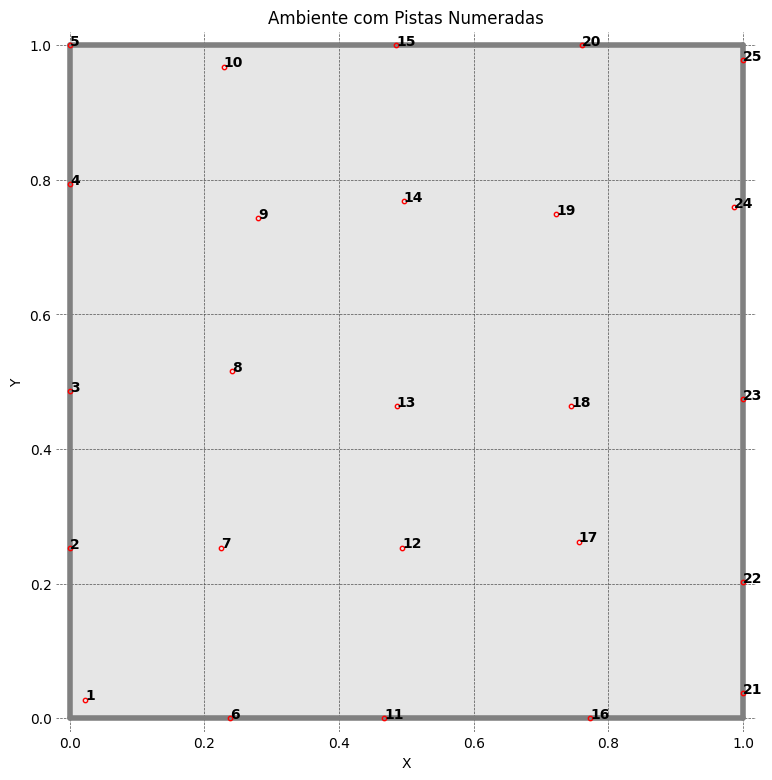

In [355]:
fig, ax = plt.subplots(1, 1, figsize=(14,7))
for i in range(NUM_OF_CUES):
    plt.annotate(text=i+1, xy=Env.objects['objects'][i],fontweight='bold', fontsize=10)
Env.plot_environment(gridlines=True, fig=fig, ax=ax,) #visualises current environment with walls and objects
plt.title('Ambiente com Pistas Numeradas')
plt.xlabel('X')
plt.ylabel('Y')
plt.show()

In [356]:
# Agent()

In [357]:
# help(Agent)

## define Ag

In [358]:
Ag = Agent(Environment=Env, params={'speed_mean':0.08,})

# agent configs
# Ag.pos = start_pos
Ag.thigmotaxis = 0.2
Ag.dt = 0.15

In [359]:
# help(Agent)

In [360]:
MINUTES = 60

### ag update

In [361]:
MINUTES*60/Ag.dt

24000.0

In [362]:
for i in range(int(MINUTES*60/Ag.dt)):
    Ag.update()

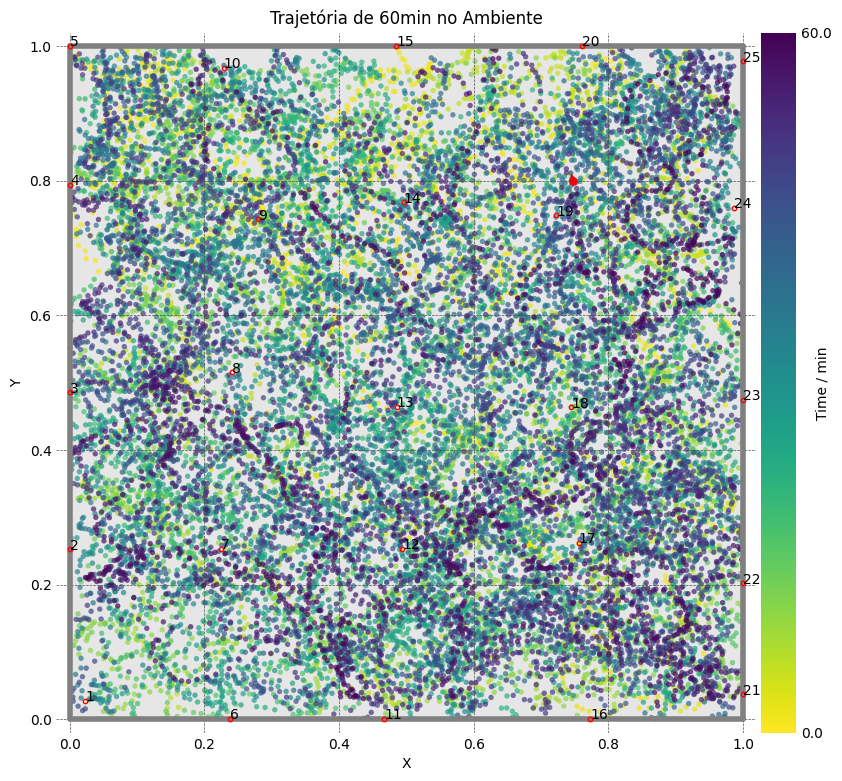

In [363]:
fig, ax = plt.subplots(1, 1, figsize=(14,7))
for i in range(NUM_OF_CUES):
    plt.annotate(text=i+1, xy=Env.objects['objects'][i], fontsize=10)
plt.title('Trajetória de 60min no Ambiente')
plt.ylabel('Y')
plt.xlabel('X')
ax = Ag.plot_trajectory(color='changing', colorbar=True, gridlines=True,fig=fig, ax=ax)

plt.show()

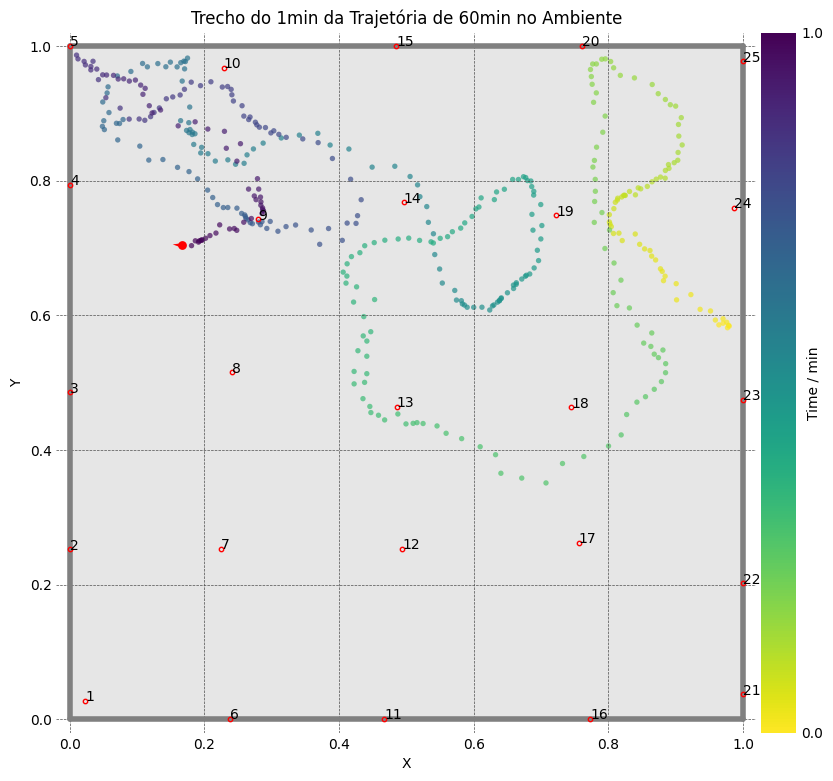

In [364]:
fig, ax = plt.subplots(1, 1, figsize=(14,7))
for i in range(NUM_OF_CUES):
    plt.annotate(text=i+1, xy=Env.objects['objects'][i], fontsize=10)
plt.title('Trecho do 1min da Trajetória de 60min no Ambiente')
plt.ylabel('Y')
plt.xlabel('X')
ax = Ag.plot_trajectory(t_start=0, t_end=60,
    color='changing', colorbar=True, gridlines=True,fig=fig, ax=ax)

plt.show()

# init dfbase

In [365]:
dfbase = pd.DataFrame(Ag.history).copy()
print(dfbase.shape)
dfbase.head(2)

(24000, 6)


,t,pos,distance_travelled,vel,rot_vel,head_direction
0,0.15,"[0.9642312527240143, 0.5857366610706362]",0.002947,"[0.01924901314411513, -0.003948870736979841]",-5.345884,"[0.9795991420207817, -0.20096149121696957]"
1,0.30,"[0.9705032534594105, 0.5882333629320741]",0.009698,"[0.04181333823597422, 0.016644679076252743]",3.874422,"[0.929093399643261, 0.3698451767149704]"


In [366]:
# # ===== subamostragem baseada em frequência alvo =====

# SAMPLE_FREQUENCY = 6  # Hz
# original_frequency = 20

# # calcula STEP (inteiro)
# STEP = max(1, int(round(original_frequency / SAMPLE_FREQUENCY)))

# print(f"Frequência original: {original_frequency:.2f} Hz")
# print(f"STEP escolhido: {STEP}")

# # copia o dataframe completo
# df = dfbase.copy().reset_index(drop=True)

# # cria coluna booleana de amostragem
# df["is_theta_sampled"] = [int(val) for val in (df.index % STEP == 0)]

# print(df.shape)
# df.head(10)

In [367]:
df = dfbase.copy()

## adding obj pos and names to dfbase

In [368]:
Env.objects.keys()

dict_keys(['objects', 'object_types', 'object_names'])

In [369]:
for i in range(NUM_OF_CUES):
    cue_dict = {f'obj_{i}_pos':[Env.objects['objects'][i] for _ in df.index],
         f'obj_{i}_name':[Env.objects['object_names'][i] for _ in df.index],}
    cue_df = pd.DataFrame(data=cue_dict, index=df.index)  
    df = pd.concat([df, cue_df], axis=1)

In [370]:
df.head()

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,obj_20_pos,obj_20_name,obj_21_pos,obj_21_name,obj_22_pos,obj_22_name,obj_23_pos,obj_23_name,obj_24_pos,obj_24_name
0,0.15,"[0.9642312527240143, 0.5857366610706362]",0.002947,"[0.01924901314411513, -0.003948870736979841]",-5.345884,"[0.9795991420207817, -0.20096149121696957]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,"[1.0, 0.03661342911221448]",GFLV,"[1.0, 0.20163715696792245]",VLKJ,"[1.0, 0.47384793352524796]",TSEH,"[0.9860697712267116, 0.7593567577581513]",KDZD,"[1.0, 0.9770626899875797]",VQEX
1,0.30,"[0.9705032534594105, 0.5882333629320741]",0.009698,"[0.04181333823597422, 0.016644679076252743]",3.874422,"[0.929093399643261, 0.3698451767149704]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,"[1.0, 0.03661342911221448]",GFLV,"[1.0, 0.20163715696792245]",VLKJ,"[1.0, 0.47384793352524796]",TSEH,"[0.9860697712267116, 0.7593567577581513]",KDZD,"[1.0, 0.9770626899875797]",VQEX
2,0.45,"[0.9770383332890855, 0.5814368921741118]",0.019127,"[0.043567198864500334, -0.04530980505308202]",-7.892169,"[0.6931093661580817, -0.7208324399913908]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,"[1.0, 0.03661342911221448]",GFLV,"[1.0, 0.20163715696792245]",VLKJ,"[1.0, 0.47384793352524796]",TSEH,"[0.9860697712267116, 0.7593567577581513]",KDZD,"[1.0, 0.9770626899875797]",VQEX
3,0.60,"[0.9796301222536734, 0.5839035026175461]",0.022705,"[0.017278593097252624, 0.0164440696228955]",10.437458,"[0.7243835452159295, 0.6893971855326954]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,"[1.0, 0.03661342911221448]",GFLV,"[1.0, 0.20163715696792245]",VLKJ,"[1.0, 0.47384793352524796]",TSEH,"[0.9860697712267116, 0.7593567577581513]",KDZD,"[1.0, 0.9770626899875797]",VQEX
4,0.75,"[0.9786310800548799, 0.5849611561629624]",0.024160,"[-0.006660281325290285, 0.007051023636108766]",10.446679,"[-0.6866770014356762, 0.7269626508282997]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,"[1.0, 0.03661342911221448]",GFLV,"[1.0, 0.20163715696792245]",VLKJ,"[1.0, 0.47384793352524796]",TSEH,"[0.9860697712267116, 0.7593567577581513]",KDZD,"[1.0, 0.9770626899875797]",VQEX


In [371]:
# df.to_parquet('legacy/datasets/traject_with_vis.gzip')
# df = pd.read_parquet('legacy/datasets/traject_with_vis.gzip')

In [372]:
# df.info()

In [373]:
# for i in range(NUM_OF_CUES):
#     cue_dict = {f'obj_{i}_pos':[Env.objects['objects'][i] for _ in ap.index],
#          f'obj_{i}_name':[Env.objects['object_names'][i] for _ in ap.index]}
#     cue_ap = pd.DataFrame(data=cue_dict, index=ap.index)  
#     ap = pd.concat([ap, cue_ap], axis=1)
#     # df[f'obj_{i}_pos'] = [Env.objects['objects'][i] for _ in df.index]
#     # df[f'obj_{i}_name'] = [Env.objects['object_names'][i] for _ in df.index]

In [374]:
# ap.head()

In [375]:
# df.shape, ap.shape

In [376]:
df.head(2)

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,obj_20_pos,obj_20_name,obj_21_pos,obj_21_name,obj_22_pos,obj_22_name,obj_23_pos,obj_23_name,obj_24_pos,obj_24_name
0,0.15,"[0.9642312527240143, 0.5857366610706362]",0.002947,"[0.01924901314411513, -0.003948870736979841]",-5.345884,"[0.9795991420207817, -0.20096149121696957]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,"[1.0, 0.03661342911221448]",GFLV,"[1.0, 0.20163715696792245]",VLKJ,"[1.0, 0.47384793352524796]",TSEH,"[0.9860697712267116, 0.7593567577581513]",KDZD,"[1.0, 0.9770626899875797]",VQEX
1,0.30,"[0.9705032534594105, 0.5882333629320741]",0.009698,"[0.04181333823597422, 0.016644679076252743]",3.874422,"[0.929093399643261, 0.3698451767149704]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,"[1.0, 0.03661342911221448]",GFLV,"[1.0, 0.20163715696792245]",VLKJ,"[1.0, 0.47384793352524796]",TSEH,"[0.9860697712267116, 0.7593567577581513]",KDZD,"[1.0, 0.9770626899875797]",VQEX


In [377]:
# ap.shape

## measure distances and visibility to objs

In [393]:
df = compute_visibility_and_distances(
    env=Env,
    df=df,
    num_of_cues=NUM_OF_CUES,
    half_fov_deg=75.,   # biologico
    min_distance=0.02,
    max_distance=1.,
)


df.head(2)

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,rel_angle_deg_obj_22,los_obj_22,dist_to_obj_23,visible_obj_23,rel_angle_deg_obj_23,los_obj_23,dist_to_obj_24,visible_obj_24,rel_angle_deg_obj_24,los_obj_24
0,0.15,"[0.964, 0.586]",0.002947,"[0.01924901314411513, -0.003948870736979841]",-5.345884,"[0.9795991420207817, -0.20096149121696957]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,-60.610556,1,0.174756,0,94.337984,1,0.392716,0,96.333545,1
1,0.30,"[0.971, 0.588]",0.009698,"[0.04181333823597422, 0.016644679076252743]",3.874422,"[0.929093399643261, 0.3698451767149704]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,-97.451793,1,0.172018,1,63.268050,1,0.390142,1,64.031094,1


In [163]:
# for i in range(NUM_OF_CUES):
#     dist_cue_dict = {f'dist_to_obj_{i}': df.apply(apply_eucd_dist, axis=1, obj=i)}
#     dist_cue_df = pd.DataFrame(data=dist_cue_dict, index=df.index)
#     df = pd.concat([df, dist_cue_df], axis=1)

In [164]:
# for i in range(NUM_OF_CUES):
#     dist_cue_dict = {f'dist_to_obj_{i}': ap.apply(apply_eucd_dist, axis=1, obj=i)}
#     dist_cue_ap = pd.DataFrame(data=dist_cue_dict, index=ap.index)
#     ap = pd.concat([ap, dist_cue_ap], axis=1)

In [165]:
# ap.head()

In [166]:
# df.columns

In [167]:
# df[[feat for feat in df.columns if feat.startswith('dist_')]].mean()

In [168]:
# fig, ax = plt.subplots(1, 1, figsize=(14,7))
# for i in range(NUM_OF_CUES):
#     plt.annotate(text=i+1, xy=Env.objects['objects'][i], fontsize=10, fontweight='bold')
# ax = Ag.plot_trajectory(color='changing', colorbar=True, gridlines=True,fig=fig, ax=ax, t_start=0, t_end=df['t'].max())

# plt.show()

In [169]:
# obj_names = [Env.objects['object_names'][i] for i in range(NUM_OF_CUES)]
# obj_dist_cols = [f'dist_to_obj_{i}' for i in range(NUM_OF_CUES)]

# # def get_position_text(x):

In [394]:
obj_names = [Env.objects['object_names'][i] for i in range(NUM_OF_CUES)]
obj_dist_cols = [f'dist_to_obj_{i}' for i in range(NUM_OF_CUES)]
obj_visible_cols = [f'visible_obj_{i}' for i in range(NUM_OF_CUES)]

In [395]:
# apd['obj_0_pos'].values[0]

In [396]:
np.round(df['pos'].values[0], 3)

array([0.964, 0.586])

In [397]:
df['pos'] = [np.round(val, 3) for val in df['pos']]

In [398]:
df.head()

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,rel_angle_deg_obj_22,los_obj_22,dist_to_obj_23,visible_obj_23,rel_angle_deg_obj_23,los_obj_23,dist_to_obj_24,visible_obj_24,rel_angle_deg_obj_24,los_obj_24
0,0.15,"[0.964, 0.586]",0.002947,"[0.01924901314411513, -0.003948870736979841]",-5.345884,"[0.9795991420207817, -0.20096149121696957]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,-60.610556,1,0.174756,0,94.337984,1,0.392716,0,96.333545,1
1,0.30,"[0.971, 0.588]",0.009698,"[0.04181333823597422, 0.016644679076252743]",3.874422,"[0.929093399643261, 0.3698451767149704]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,-97.451793,1,0.172018,1,63.268050,1,0.390142,1,64.031094,1
2,0.45,"[0.977, 0.581]",0.019127,"[0.043567198864500334, -0.04530980505308202]",-7.892169,"[0.6931093661580817, -0.7208324399913908]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,-31.762135,1,0.178587,0,133.212162,1,0.396730,0,132.799725,1
3,0.60,"[0.98, 0.584]",0.022705,"[0.017278593097252624, 0.0164440696228955]",10.437458,"[0.7243835452159295, 0.6893971855326954]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,-123.291485,1,0.175462,1,44.435155,1,0.393571,1,43.504752,1
4,0.75,"[0.979, 0.585]",0.024160,"[-0.006660281325290285, 0.007051023636108766]",10.446679,"[-0.6866770014356762, 0.7269626508282997]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,147.331168,1,0.174500,1,-45.689579,1,0.392625,1,-46.433633,1


## create positions

In [399]:
dfp = apply_cps_to_positions_with_vizz(df, obj_dist_cols, obj_visible_cols)
dfp.shape

(24000, 159)

In [400]:
dfp['position_state_id'] = dfp.groupby(['position_state']).ngroup() + 1 
dfp['position_state_id'].nunique()

2649

In [416]:
dfp['position_state_id'].value_counts()

position_state_id
2324    146
2275    130
2252    127
2236    124
919     115
       ... 
1486      1
1568      1
1603      1
947       1
1294      1
Name: count, Length: 2649, dtype: int64

In [401]:
dfp.groupby('n_visible_objects')['position_state_id'].value_counts()

n_visible_objects  position_state_id
0                  1                     88
1                  2324                 146
                   2252                 127
                   919                  115
                   620                   58
                                       ... 
20                 1824                   1
                   1989                   1
                   2102                   1
                   2192                   1
                   2618                   1
Name: count, Length: 5299, dtype: int64

In [402]:
dfp[dfp['n_visible_objects'] == 2]['position_state_id'].value_counts()[:4]

position_state_id
2275    130
2236    124
1288    104
2460     88
Name: count, dtype: int64

In [403]:
dfp[dfp['n_visible_objects'] == 3]['position_state_id'].value_counts()[:4]

position_state_id
669     81
2249    78
2399    77
1296    77
Name: count, dtype: int64

In [404]:
dfp[dfp['n_visible_objects'] == 4]['position_state_id'].value_counts()[:4]

position_state_id
2075    59
2178    45
670     43
2147    42
Name: count, dtype: int64

In [413]:
dfp[dfp['n_visible_objects'] == 5]['position_state_id'].value_counts()[:4]

position_state_id
2411    44
2624    42
2611    39
2284    38
Name: count, dtype: int64

<Axes: >

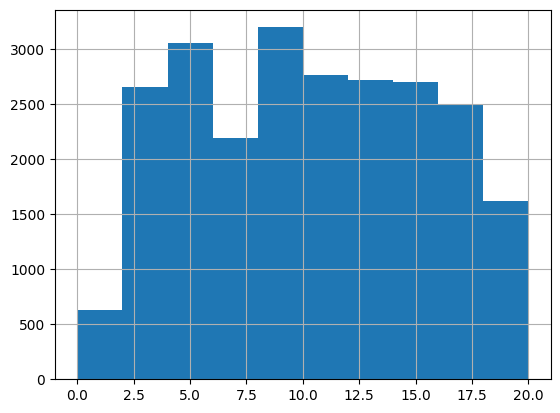

In [406]:
dfp['n_visible_objects'].hist()

In [183]:
# ap.iloc[0:100_000].shape

In [184]:
dfp[dfp['position_state_id'] == 1].head(10)

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,rel_angle_deg_obj_23,los_obj_23,dist_to_obj_24,visible_obj_24,rel_angle_deg_obj_24,los_obj_24,position_state,mean_distance_visible,n_visible_objects,position_state_id
1,0.30,"[0.43, 0.995]",0.024639,"[0.012446556790744653, 0.07959584984652546]",7.260726,"[0.15449447585045925, 0.9879936522729749]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,-104.069479,1,0.569779,0,-82.885616,1,AAAAAAAAAAAAAAAAAAAA,NaN,0,1
22,3.45,"[0.644, 0.863]",0.330655,"[-0.016866025106030413, -0.09552858362473401]",-10.508934,"[-0.17386570923664185, -0.9847693715543957]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,83.211993,1,0.373967,0,117.827788,1,AAAAAAAAAAAAAAAAAAAA,NaN,0,1
41,6.30,"[0.851, 0.893]",0.651034,"[0.019368963231757668, 0.18545511269336457]",1.889714,"[0.10387518287015966, 0.9945903409865243]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,-128.711672,1,0.171260,0,-54.732781,1,AAAAAAAAAAAAAAAAAAAA,NaN,0,1
42,6.45,"[0.848, 0.919]",0.677104,"[-0.019778162502415153, 0.17267508011066174]",1.454035,"[-0.11379573050036143, 0.9935041679428874]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,-145.639881,1,0.162953,0,-75.712521,1,AAAAAAAAAAAAAAAAAAAA,NaN,0,1
43,6.60,"[0.853, 0.936]",0.694649,"[0.03649630525135006, 0.11112306501645408]",-2.875850,"[0.3120332235379435, 0.9500711907054754]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,-124.830559,1,0.152521,0,-56.125073,1,AAAAAAAAAAAAAAAAAAAA,NaN,0,1
45,6.90,"[0.849, 0.957]",0.728568,"[0.06786608878454134, 0.10714616284148493]",-11.961186,"[0.5350906408452403, 0.8447946532026763]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,-112.949849,1,0.152039,0,-50.015578,1,AAAAAAAAAAAAAAAAAAAA,NaN,0,1
47,7.20,"[0.844, 0.968]",0.758195,"[0.04743743791028784, 0.10024975405205898]",-15.713883,"[0.42772334487302993, 0.9039096969557451]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,-120.399848,1,0.156097,0,-61.170700,1,AAAAAAAAAAAAAAAAAAAA,NaN,0,1
49,7.50,"[0.82, 0.978]",0.789818,"[-0.04280549765164714, 0.08007387058345991]",-7.806816,"[-0.47144061328416204, 0.8818978104895449]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,-170.869770,1,0.180157,0,-118.390650,1,AAAAAAAAAAAAAAAAAAAA,NaN,0,1
143,21.60,"[0.871, 0.551]",2.266290,"[0.1323345768468191, 0.046532053304551756]",-3.739223,"[0.9433795813038561, 0.3317151874409149]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,41.640436,1,0.444923,0,53.747320,1,AAAAAAAAAAAAAAAAAAAA,NaN,0,1
144,21.75,"[0.893, 0.558]",2.289638,"[0.14914261225834244, 0.044540190399792554]",-0.319403,"[0.9581837749186952, 0.2861535487855413]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,48.608887,1,0.432472,0,59.072445,1,AAAAAAAAAAAAAAAAAAAA,NaN,0,1


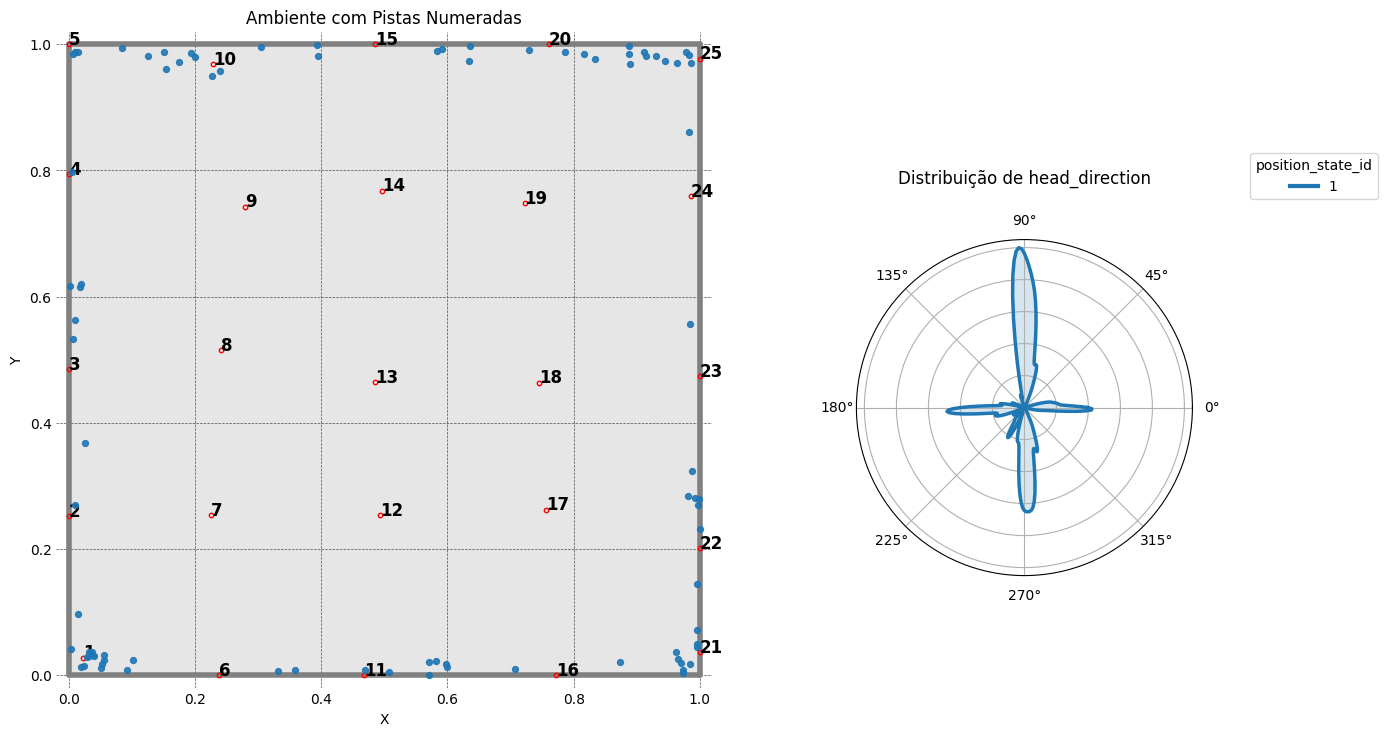

In [405]:
fig, axes = plot_position_states_with_env_and_circular_kde(
    df=dfp,
    ids=[1,],
    Env=Env,
    num_of_cues=NUM_OF_CUES,
    bandwidth=0.05,
    fill=True,
    show_mean_direction=False,
)

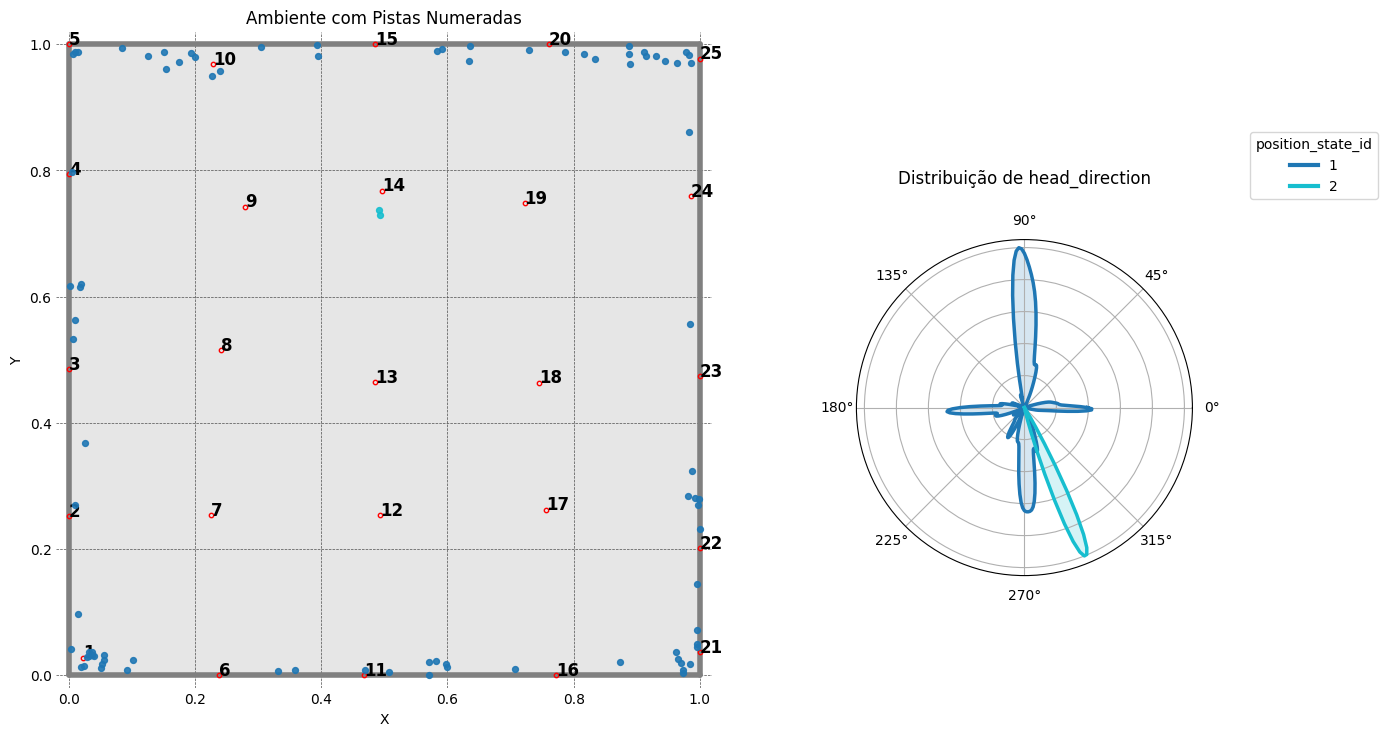

In [414]:
fig, axes = plot_position_states_with_env_and_circular_kde(
    df=dfp,
    ids=[1, 2],
    Env=Env,
    num_of_cues=NUM_OF_CUES,
    bandwidth=0.05,
    fill=True,
    show_mean_direction=False,
)

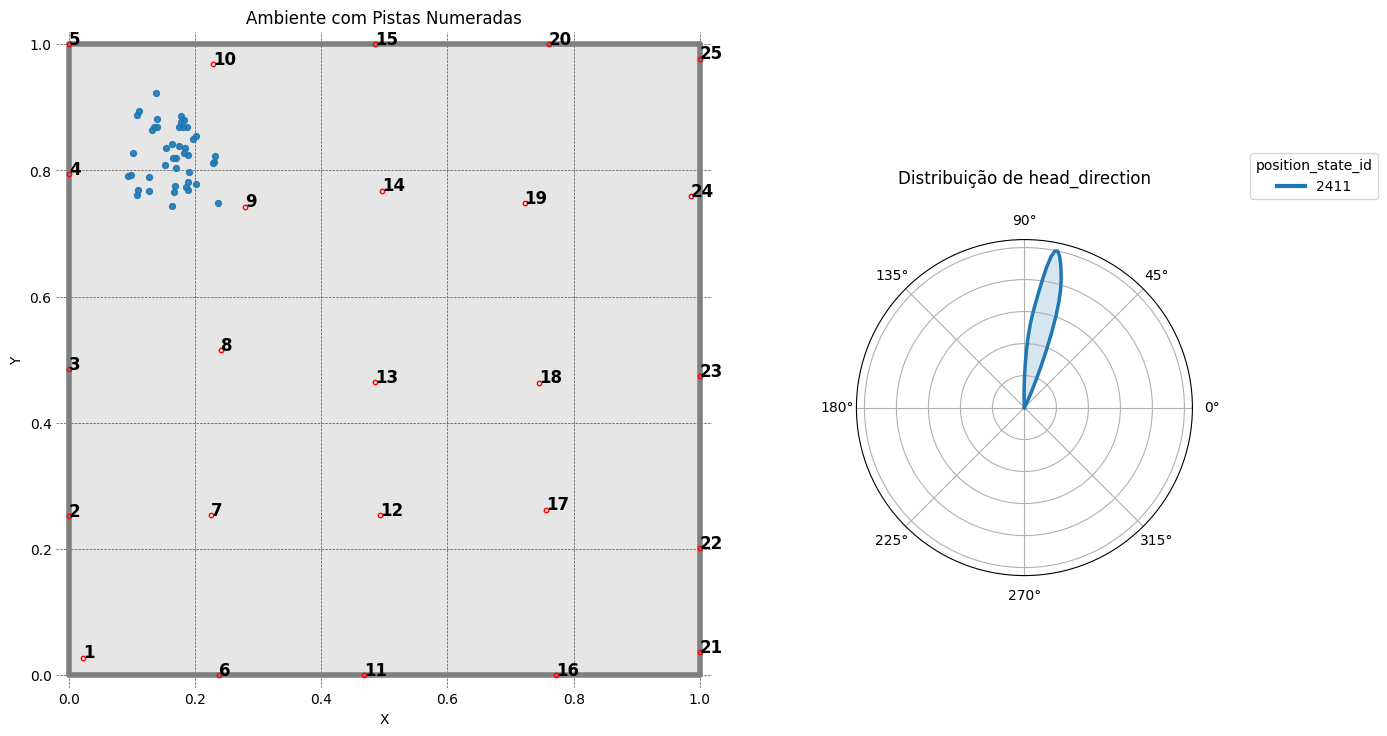

In [415]:
fig, axes = plot_position_states_with_env_and_circular_kde(
    df=dfp,
    ids=[2411],
    Env=Env,
    num_of_cues=NUM_OF_CUES,
    bandwidth=0.05,
    fill=True,
    show_mean_direction=False,
)

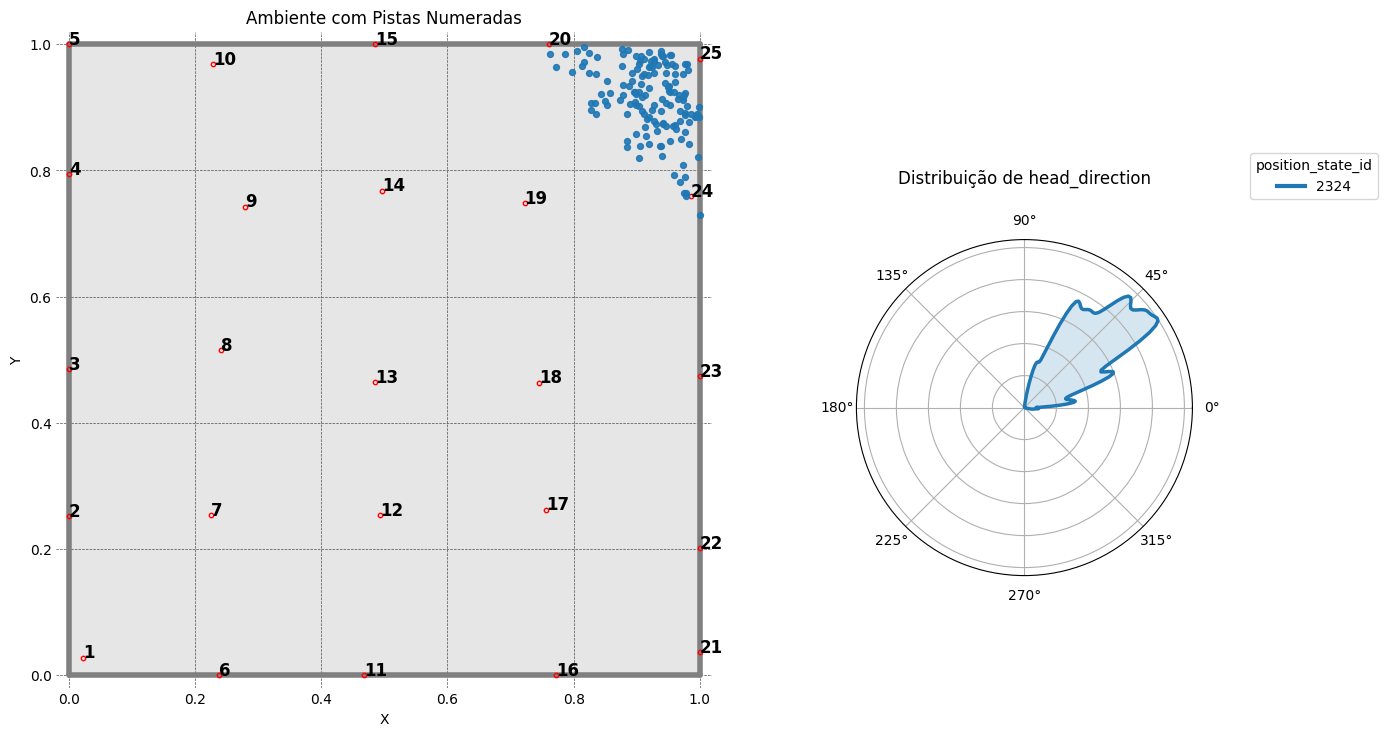

In [417]:
fig, axes = plot_position_states_with_env_and_circular_kde(
    df=dfp,
    ids=[2324],
    Env=Env,
    num_of_cues=NUM_OF_CUES,
    bandwidth=0.05,
    fill=True,
    show_mean_direction=False
)

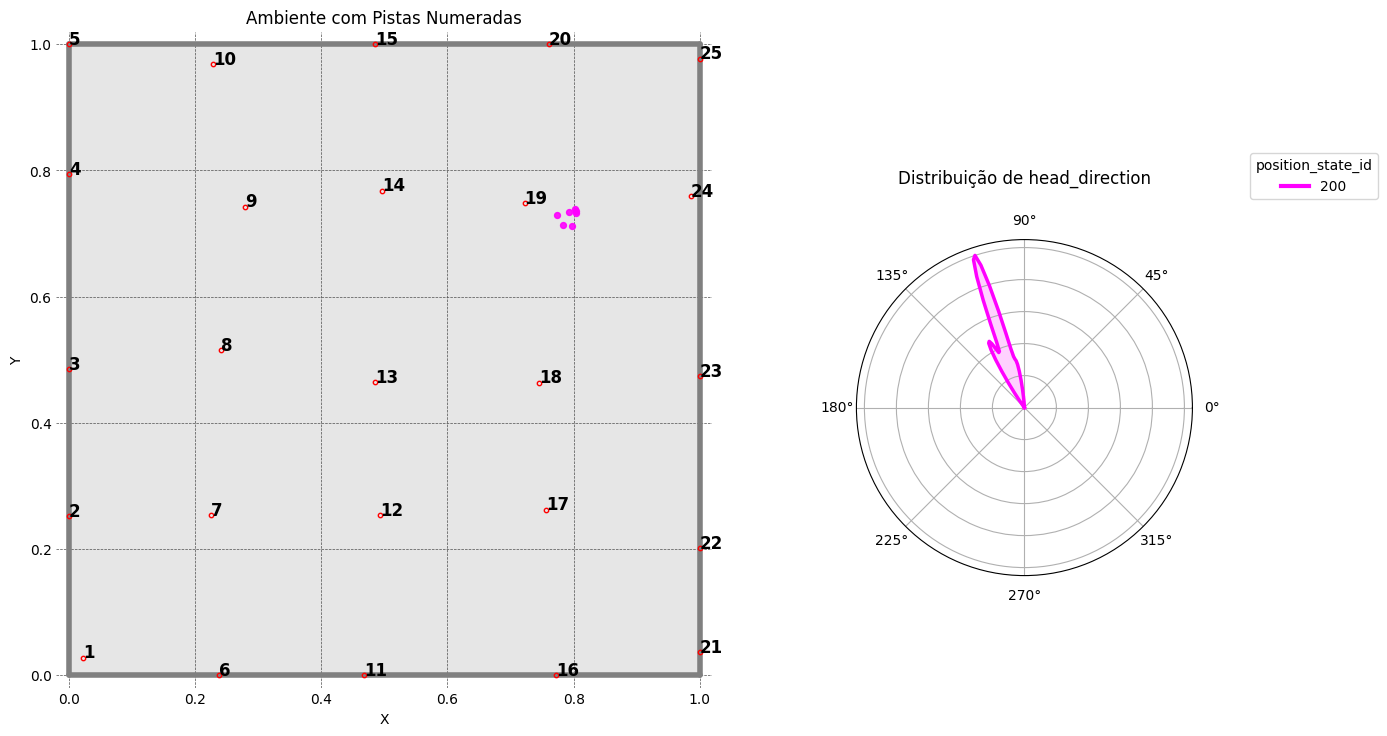

In [408]:
fig, axes = plot_position_states_with_env_and_circular_kde(
    df=dfp,
    ids=[200],
    Env=Env,
    num_of_cues=NUM_OF_CUES,
    colors=["magenta"],
    bandwidth=0.05,
    fill=True,
    show_mean_direction=False
)

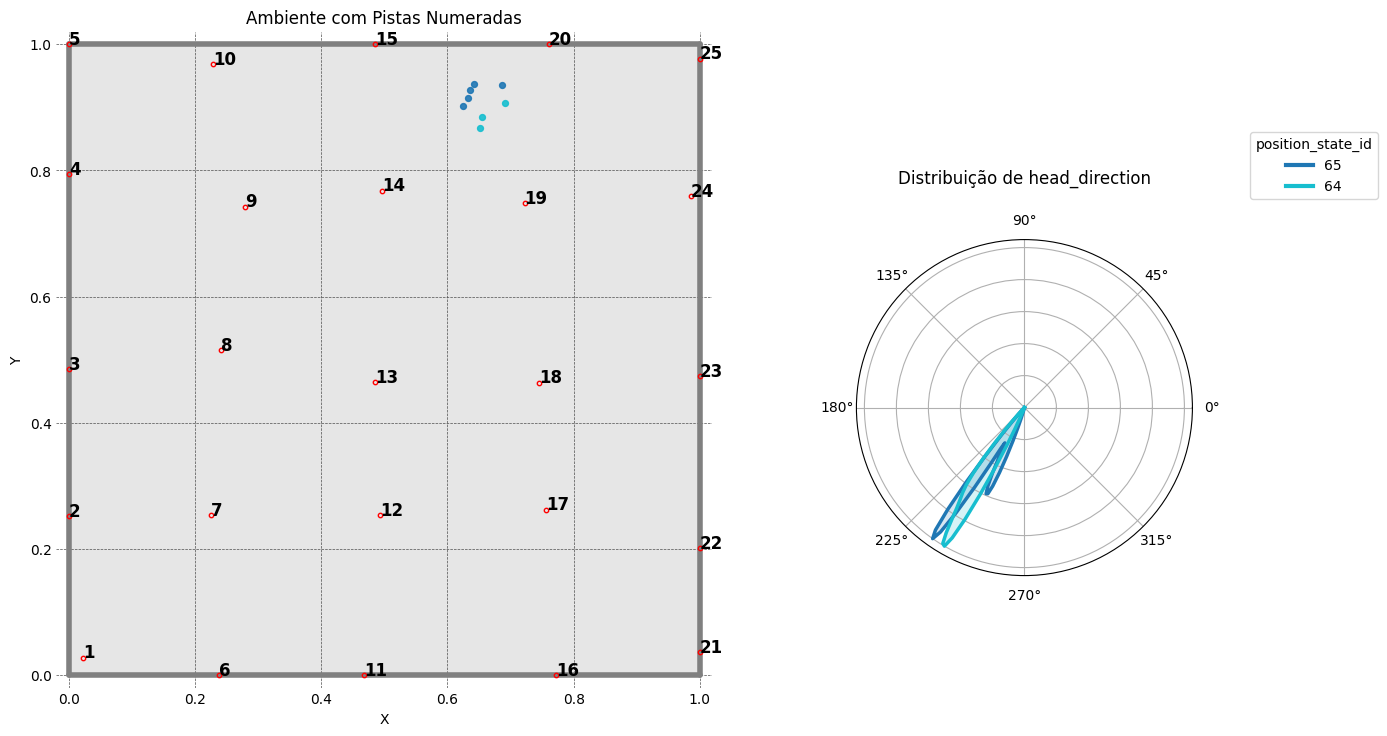

In [409]:
fig, axes = plot_position_states_with_env_and_circular_kde(
    df=dfp,
    ids=[65, 64],
    Env=Env,
    num_of_cues=NUM_OF_CUES,
    bandwidth=0.05,
    fill=True,
    show_mean_direction=False
)

In [410]:
colors = {
    160: "grey",
    207: "red",
    144: "orange",
    # 2: "yellow",
}

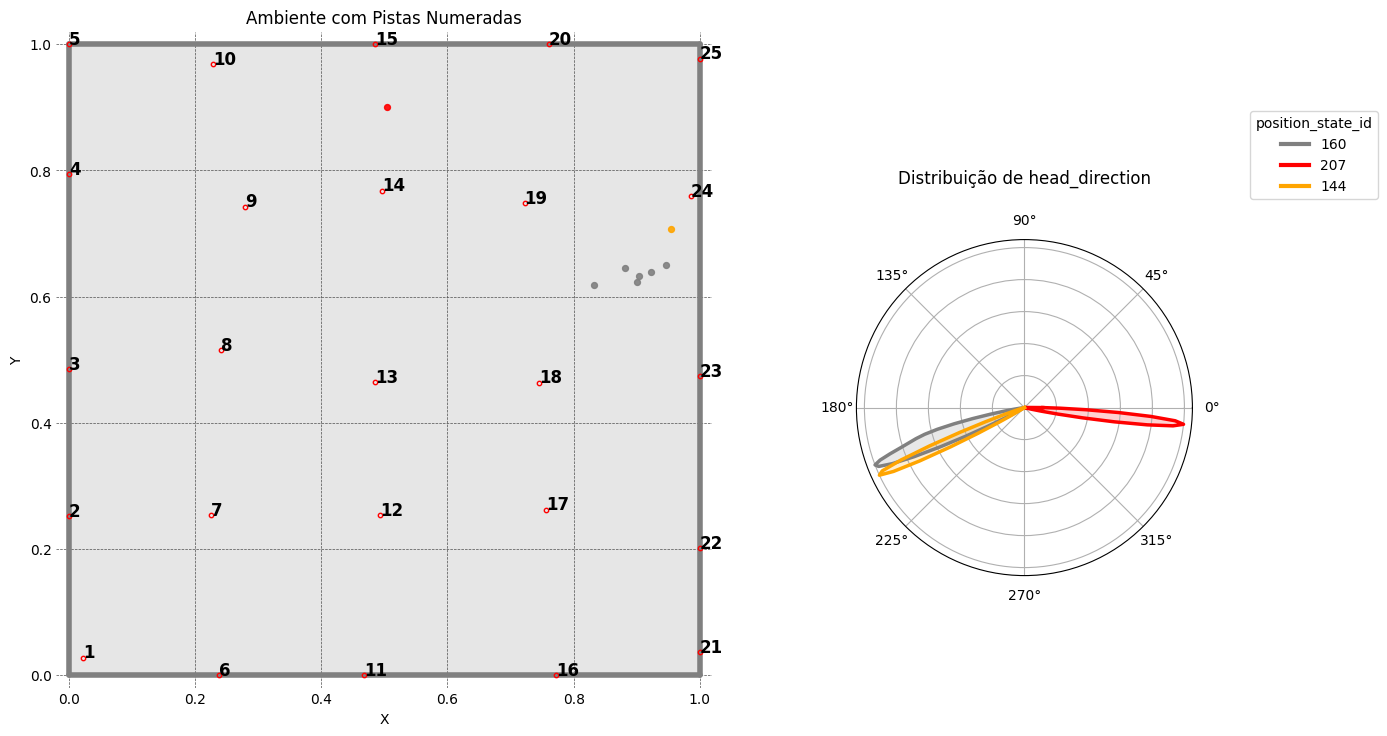

In [411]:
fig, axes = plot_position_states_with_env_and_circular_kde(
    df=dfp,
    ids=[160, 207, 144,],
    Env=Env,
    num_of_cues=NUM_OF_CUES,
    colors=colors,
    bandwidth=0.05,
    fill=True,
    show_mean_direction=False
)

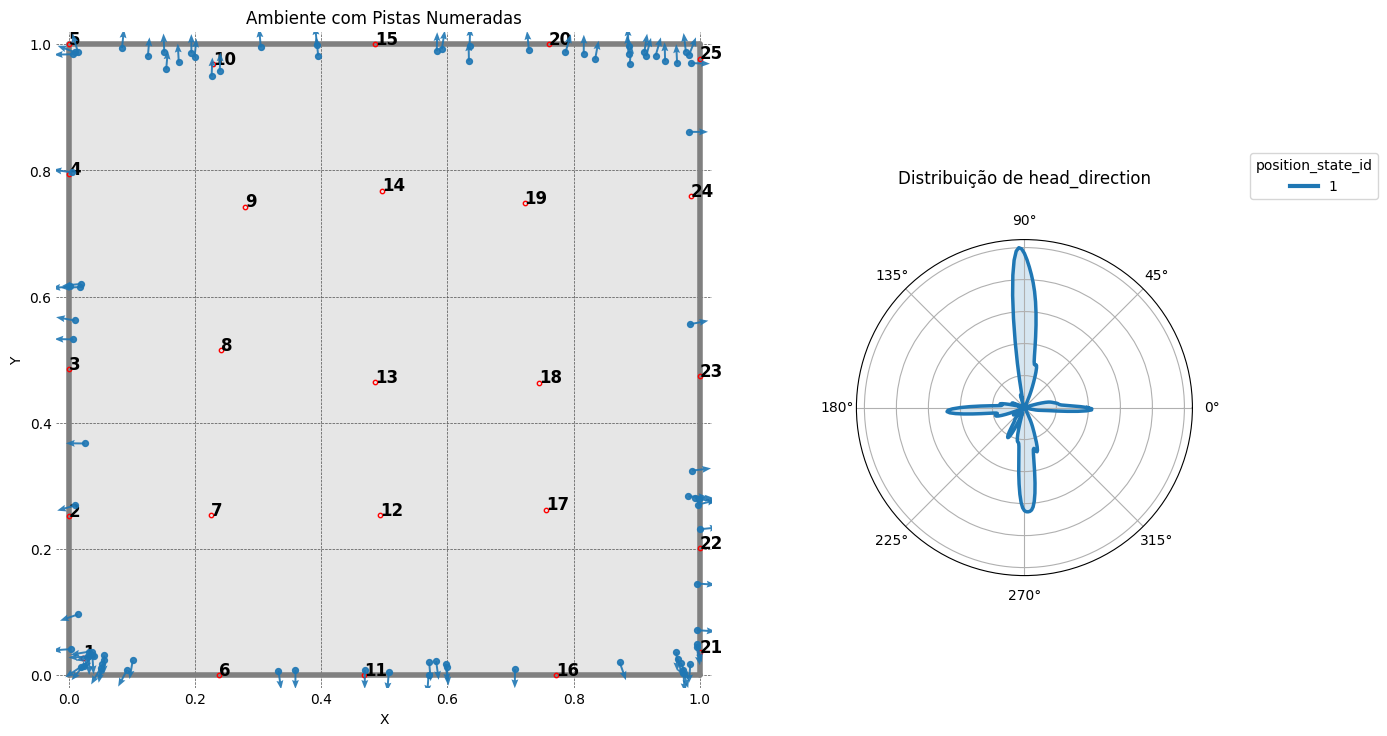

In [412]:
fig, axes = plot_position_states_with_env_and_circular_kde(
    df=dfp,
    ids=[1,],
    Env=Env,
    num_of_cues=NUM_OF_CUES,
    bandwidth=0.05,
    fill=True,
    show_mean_direction=False,
    show_env_arrows=True,
    arrow_every=1,
)

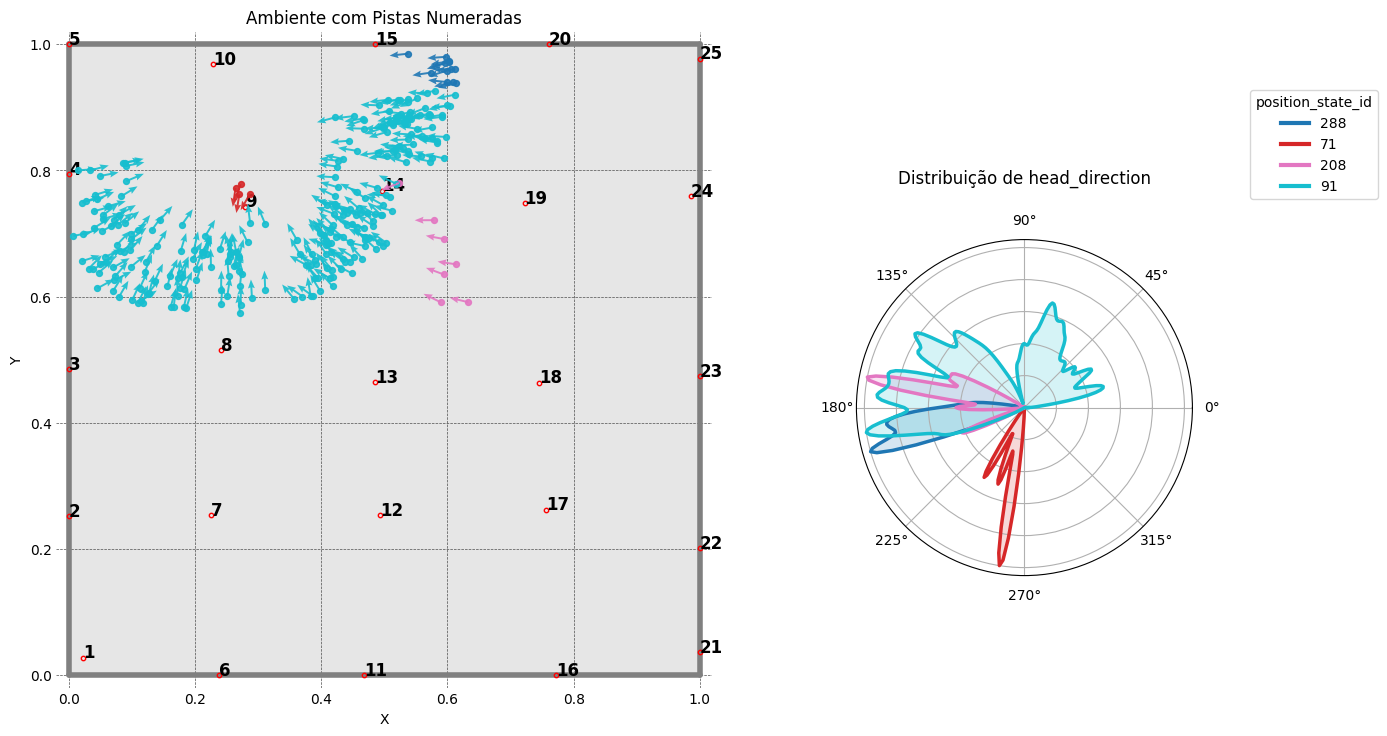

In [238]:
fig, axes = plot_position_states_with_env_and_circular_kde(
    df=dfp,
    ids=[288 ,71, 208, 91],
    Env=Env,
    num_of_cues=NUM_OF_CUES,
    bandwidth=0.05,
    fill=True,
    show_mean_direction=False,
    show_env_arrows=True,
    arrow_every=1,
)

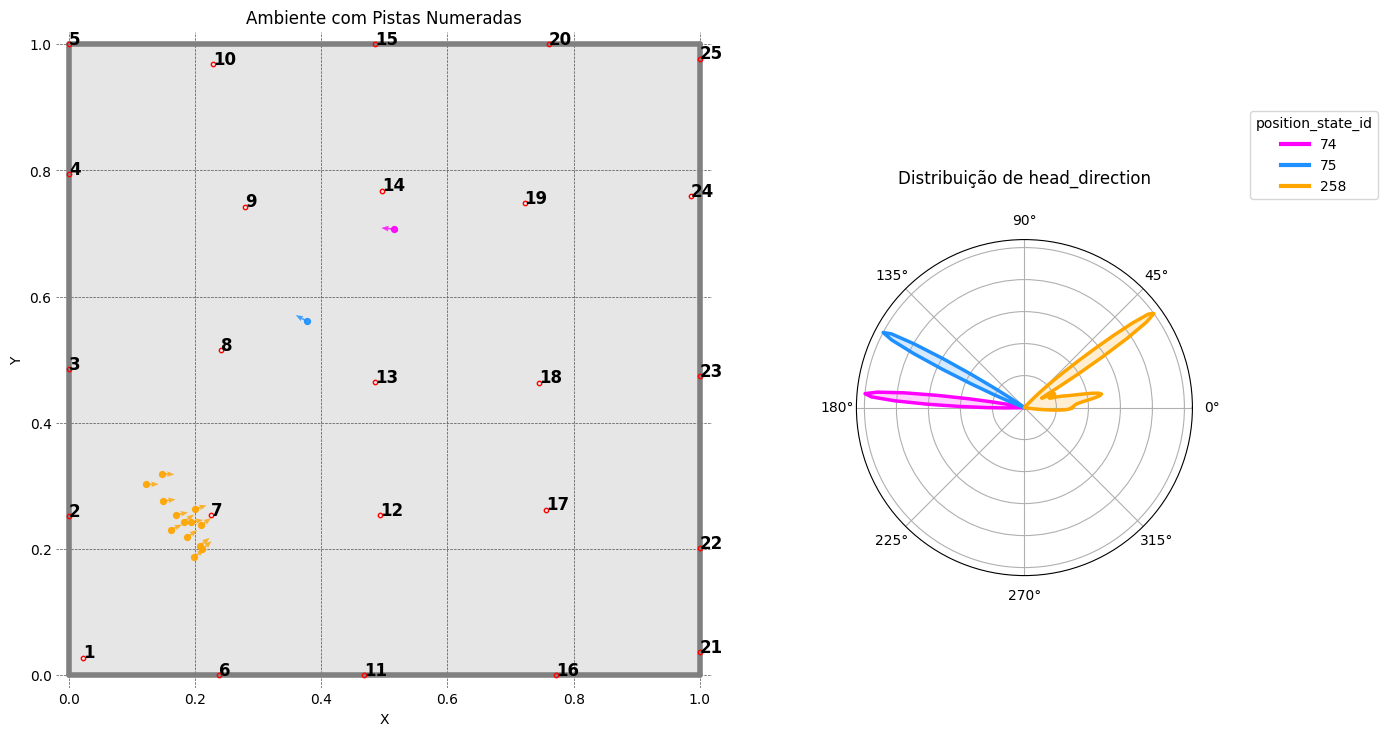

(<Figure size 1600x800 with 2 Axes>,
 (<Axes: title={'center': 'Ambiente com Pistas Numeradas'}, xlabel='X', ylabel='Y'>,
  <PolarAxes: title={'center': 'Distribuição de head_direction'}>))

In [237]:
plot_position_states_with_env_and_circular_kde(
    df=dfp,
    ids=[74, 75, 258],
    Env=Env,
    colors=["magenta", "dodgerblue", "orange"],
    show_env_arrows=True,
    arrow_color_mode="match_id",
    bandwidth=0.05,
    arrow_scale=0.02,
    arrow_width=0.0025,
    arrow_alpha=0.8,
)

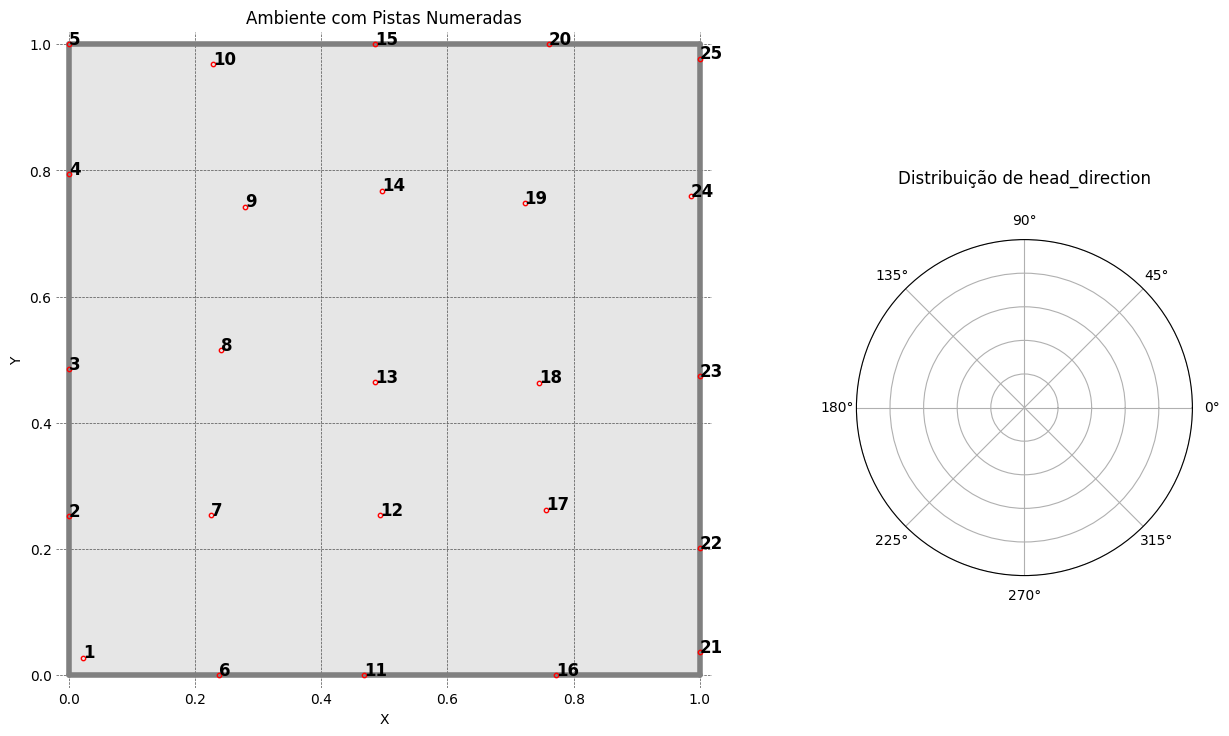

(<Figure size 1600x800 with 2 Axes>,
 (<Axes: title={'center': 'Ambiente com Pistas Numeradas'}, xlabel='X', ylabel='Y'>,
  <PolarAxes: title={'center': 'Distribuição de head_direction'}>))

In [241]:
plot_position_states_with_env_and_circular_kde(
    df=dfp,
    ids=[0],
    Env=Env,
    colors=["magenta",],
    show_env_arrows=True,
    arrow_color_mode="match_id",
    bandwidth=0.05,
    arrow_scale=0.02,
    arrow_width=0.0025,
    arrow_alpha=0.8,
)

In [426]:
np.mean([len(val) for val in dfp['position_state']])

20.0

In [220]:
dfp[dfp['position_state'].str.startswith('PIPZ')]['position_state_id'].unique()

array([291, 295, 310, 314, 304, 292, 296, 303, 313, 307, 312, 315, 308,
       298, 305, 294, 302, 311, 300, 301, 293, 306, 309, 297, 299])

In [223]:
dfp[dfp['position_state_id'].isin([291, 209, 213,])]['position_state'].unique()

array(['PIPZAAAAAAAAAAAAAAAA', 'MOWWCEPVNFTUAAAAAAAA',
       'MOWWDCTACEPVAAAAAAAA'], dtype=object)

In [138]:
# apd_2 = apply_cps_to_positions(ap.iloc[100_000:200_000], obj_dist_cols)

In [139]:
# for i in range(2, 11):
#     apd_2 = apply_cps_to_positions(ap.iloc[(i-1)*100_000:i*100_000], obj_dist_cols)
#     print(f"{(i-1)*100_000}:{i*100_000} pronto")
#     apd_2.to_parquet(f'apd{i}.gzip')

In [140]:
# ap.iloc[1_000_000:]

In [141]:
# apd = apply_cps_to_positions(ap.iloc[1_000_000:], obj_dist_cols)
# apd.shape

In [142]:
# apd.to_parquet(f'legacy/datasets/apd11.gzip')

## apd loop

In [143]:
# apd_list = [pd.read_parquet(f'apd{i}.gzip') for i in range(1, 12)]


# # apd_full = pd.concat(apd_list, ignore_index=True)
# # apd_full.shape

In [144]:
# for i in range(2, 12):
#     print(f'apd{i}.gzip')

In [145]:
# apd_full = pd.concat(apd_list,)

In [146]:
# apd_full.shape

In [418]:
len(dfp), dfp['position_state'].nunique()/len(dfp), dfp['position_state'].nunique()

(24000, 0.110375, 2649)

In [419]:
# apd[['pos','position_state_id']].sample(5)

In [437]:
num_unique_pos = dfp['position_state'].nunique()
num_unique_pos

2649

In [438]:
dfp['normalized_position_state_id']  = (dfp['position_state_id'] / dfp['position_state_id'].nunique())
dfp[['position_state_id', 'normalized_position_state_id']].sample(5)

,position_state_id,normalized_position_state_id
6690,691,0.260853
13877,1073,0.405059
7420,620,0.234051
5725,1689,0.637599
14515,1411,0.532654


In [439]:
# apd.head()

In [440]:
# apd[['obj_0_name', 'obj_0_pos']].values

## get change of pos

In [441]:
dfp['last_position_state_id'] = (dfp['position_state_id'].shift(1))
dfp.shape

(24000, 163)

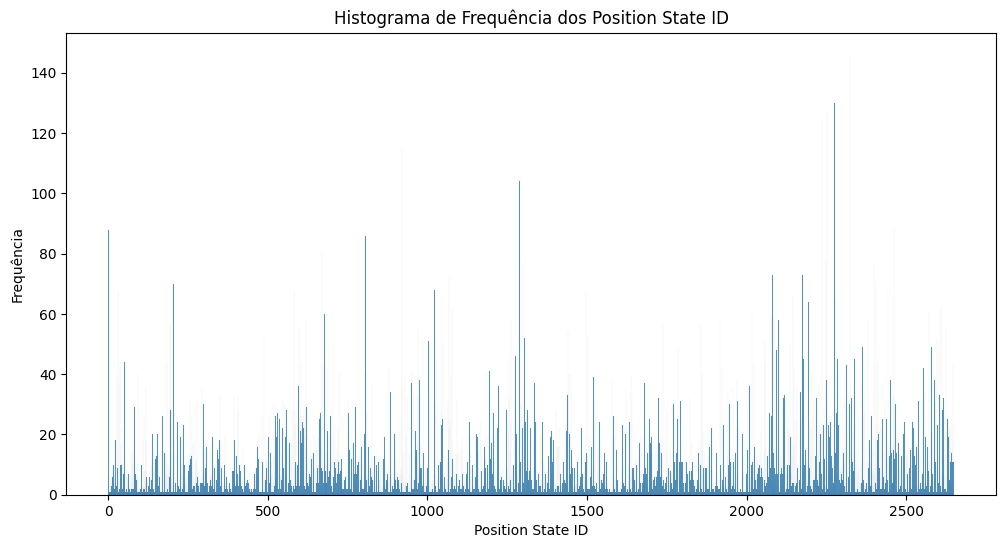

In [442]:
fig, ax = plt.subplots(figsize=(12, 6))
plt.title('Histograma de Frequência dos Position State ID')
sns.histplot(dfp['position_state_id'],binwidth=1,)
plt.ylabel('Frequência')
plt.xlabel('Position State ID')
plt.show()

In [443]:
change_dict_ = {'change_of_position_state':[int(pos!=last_pos) for pos, last_pos in zip(dfp['position_state_id'].astype('float'), dfp['last_position_state_id'])]}
change_dict_df = pd.DataFrame(change_dict_)

print(change_dict_df.shape)
# dfp = pd.concat([dfp, change_dict_df], ignore_index=True, axis=0)

(24000, 1)


In [444]:
dfp.shape

(24000, 163)

In [445]:
dfp['change_of_position_state'] = (change_dict_df['change_of_position_state'])

In [446]:
dfp.shape

(24000, 163)

In [447]:
# dfp['change_of_position_state'].values

In [448]:
dfp[['position_state', 'position_state_id', 'last_position_state_id', 'change_of_position_state']].iloc[8:12]

,position_state,position_state_id,last_position_state_id,change_of_position_state
8,KDZDAOWPVQEXXYCOMOWW,1261,1825.0,1
9,PIPZAOWPYGWPXYCOMOWW,1826,1261.0,1
10,KDZDAOWPVQEXXYCOMOWW,1261,1826.0,1
11,AOWPPIPZYGWPMOWWCCOO,160,1261.0,1


In [449]:
dfp[dfp['change_of_position_state'] == 1][['position_state_id', 'last_position_state_id', 'change_of_position_state']].head()

,position_state_id,last_position_state_id,change_of_position_state
0,2174,NaN,1
1,1288,2174.0,1
2,2178,1288.0,1
3,1296,2178.0,1
4,1265,1296.0,1


In [450]:
dfp[dfp['change_of_position_state'] == 1].shape

(21251, 163)

In [451]:
dfp['change_of_position_state'].mean()

0.8854583333333333

# train df

In [452]:
dfc = dfp.copy() #dfp[dfp['change_of_position_state'] == 1].iloc[1:].reset_index(drop=True).copy()
dfc.shape

(24000, 163)

In [453]:
dfc.head(2)

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,visible_obj_24,rel_angle_deg_obj_24,los_obj_24,position_state,mean_distance_visible,n_visible_objects,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.15,"[0.964, 0.586]",0.002947,"[0.01924901314411513, -0.003948870736979841]",-5.345884,"[0.9795991420207817, -0.20096149121696957]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0,96.333545,1,TSEHVLKJGFLVAAAAAAAA,0.351466,3,2174,0.820687,NaN,1
1,0.30,"[0.971, 0.588]",0.009698,"[0.04181333823597422, 0.016644679076252743]",3.874422,"[0.929093399643261, 0.3698451767149704]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,1,64.031094,1,KDZDVQEXAAAAAAAAAAAA,0.281080,2,1288,0.486221,2174.0,1


In [454]:
dfc.columns

Index(['t', 'pos', 'distance_travelled', 'vel', 'rot_vel', 'head_direction',
       'obj_0_pos', 'obj_0_name', 'obj_1_pos', 'obj_1_name',
       ...
       'visible_obj_24', 'rel_angle_deg_obj_24', 'los_obj_24',
       'position_state', 'mean_distance_visible', 'n_visible_objects',
       'position_state_id', 'normalized_position_state_id',
       'last_position_state_id', 'change_of_position_state'],
      dtype='object', length=163)

In [455]:
columns_to_keep = [
    't',
    'pos',
    'distance_travelled',
    'vel',
    'rot_vel',
    'head_direction',
    'position_state',
    'position_state_id',
    'normalized_position_state_id',
    'last_position_state_id',
    'change_of_position_state',
]

### save dfc

In [456]:
save_dfc = True

In [457]:
# print(dfc[columns_to_keep].shape)
if save_dfc:
    dfc[columns_to_keep].to_parquet(r'/home/mgteus/workspace/navitrans/legacy/datasets/bert_trainset_squared_25_with_vis.gzip', index=False)

In [458]:
dfc[columns_to_keep].head(5)

,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.15,"[0.964, 0.586]",0.002947,"[0.01924901314411513, -0.003948870736979841]",-5.345884,"[0.9795991420207817, -0.20096149121696957]",TSEHVLKJGFLVAAAAAAAA,2174,0.820687,NaN,1
1,0.30,"[0.971, 0.588]",0.009698,"[0.04181333823597422, 0.016644679076252743]",3.874422,"[0.929093399643261, 0.3698451767149704]",KDZDVQEXAAAAAAAAAAAA,1288,0.486221,2174.0,1
2,0.45,"[0.977, 0.581]",0.019127,"[0.043567198864500334, -0.04530980505308202]",-7.892169,"[0.6931093661580817, -0.7208324399913908]",TSEHVLKJGFLVTKVXAAAA,2178,0.822197,1288.0,1
3,0.60,"[0.98, 0.584]",0.022705,"[0.017278593097252624, 0.0164440696228955]",10.437458,"[0.7243835452159295, 0.6893971855326954]",KDZDVQEXXYCOAAAAAAAA,1296,0.489241,2178.0,1
4,0.75,"[0.979, 0.585]",0.024160,"[-0.006660281325290285, 0.007051023636108766]",10.446679,"[-0.6866770014356762, 0.7269626508282997]",KDZDPIPZAOWPVQEXXYCO,1265,0.477539,1296.0,1


In [214]:
def plot_environment_by_state(dfc, env=None, point_size=5):
    """
    Plota o ambiente (x, y) colorido por position_state_id.

    Parameters
    ----------
    dfc : DataFrame
        Deve conter colunas:
            - 'pos' (array [x, y])
            - 'position_state_id'
    env : RatInABox Environment (opcional)
        Se fornecido, plota limites e objetos
    """

    # ---- extrai posições ----
    pos_array = np.vstack(dfc["pos"].values)
    x = pos_array[:, 0]
    y = pos_array[:, 1]

    # ---- estados ----
    states = dfc["position_state_id"].values

    # mapeia estados únicos para cores
    unique_states = np.unique(states)
    n_states = len(unique_states)

    # colormap
    cmap = plt.cm.get_cmap("tab20", n_states)

    state_to_color = {s: cmap(i) for i, s in enumerate(unique_states)}
    colors = np.array([state_to_color[s] for s in states])

    # ---- plot ----
    plt.figure(figsize=(8, 8))
    plt.scatter(x, y, c=states,cmap='viridis', s=point_size)

    # ---- opcional: desenhar ambiente ----
    if env is not None:
        # limites do ambiente
        if hasattr(env, "extent"):
            xmin, xmax, ymin, ymax = env.extent
            plt.xlim(xmin, xmax)
            plt.ylim(ymin, ymax)

        # objetos
        if hasattr(env, "objects"):
            obj_pos = np.array(env.objects["objects"])
            plt.scatter(
                obj_pos[:, 0],
                obj_pos[:, 1],
                c="black",
                s=80,
                marker="x",
                label="objects"
            )

    plt.title("Environment colored by position_state_id")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.axis("equal")

    # legenda simplificada (opcional, pode ficar pesada)
    # plt.legend()

    plt.show()

/tmp/ipykernel_59908/4159453985.py:28: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap("tab20", n_states)


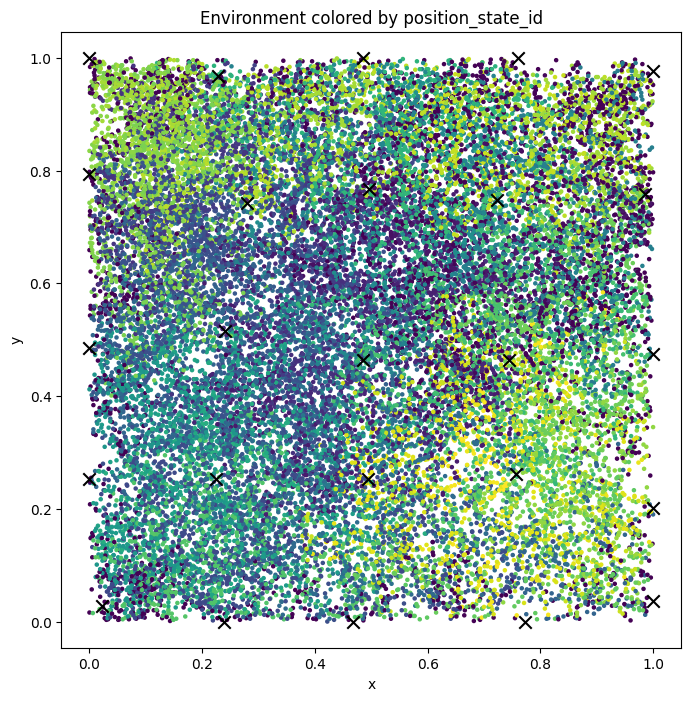

In [215]:
plot_environment_by_state(dfc, env=Env)

/tmp/ipykernel_59908/4159453985.py:28: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap("tab20", n_states)


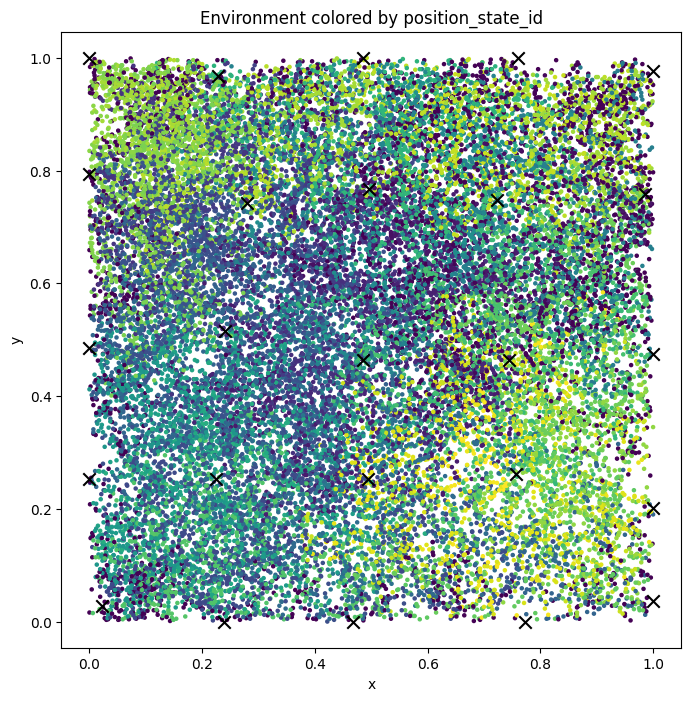

In [216]:
plot_environment_by_state(dfp, env=Env)

# FIM